In [3]:
import torch

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [5]:
device

'cpu'

In [6]:
import warnings
warnings.filterwarnings('ignore')

# Model Evaluation

In [7]:
# Model class
import torch.nn.functional as F
import torch.optim as op
from torch.utils.data import IterableDataset
from torch.utils.data import DataLoader

class Word2Vec(torch.nn.Module):
  def __init__(self, vocab_size, embedding_dim):
    super().__init__()
    self.input_embedding_layer = torch.nn.Embedding(vocab_size, embedding_dim)
    self.output_embedding_layer = torch.nn.Embedding(vocab_size, embedding_dim)

  def forward(self, x, y):
    e1 = self.input_embedding_layer(x)
    e2 = self.output_embedding_layer(y)

    return (e1 * e2).sum(dim=1)

In [8]:
# Vocabulary
import pandas as pd
word_int = pd.read_csv('vocabulary.csv').drop('Unnamed: 0', axis='columns')

In [9]:
# Model loading
model = torch.load('Word2Vec_hindi_best_model.bin', weights_only=False, map_location=torch.device(device))

## Quantitative Evaluation

### Establishing human similarity baseline using Hindi (RG-63)

In [ ]:
!git clone https://github.com/ashwinivd/similarity_hindi.git

Cloning into 'similarity_hindi'...
remote: Enumerating objects: 57, done.
remote: Counting objects: 100% (57/57), done.
remote: Compressing objects: 100% (53/53), done.
remote: Total 57 (delta 11), reused 26 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (57/57), 1.50 MiB | 14.45 MiB/s, done.
Resolving deltas: 100% (11/11), done.


In [ ]:
!ls similarity_hindi/

papers	README.md  rg-63


In [ ]:
# contains data for both qualitative and quantitative evaluation
!ls evaluation_data/

high_freq.csv  Hin-RG63.txt  low_freq.csv  med_freq.csv


### creating human similarity data based on which words are in our vocabulary

In [ ]:
word_int['Word'].values

array(['के', 'है', 'में', ..., 'ॠणों', 'अर्थानुसार', '<UNK>'],
      dtype=object)

In [ ]:
with open('evaluation_data/Hin-RG63.txt', 'r', encoding='utf-8') as f, open('evaluation_data/human_similarity.txt', 'w') as w:
  c=0
  lines = f.readlines()
  for i in range(len(lines)):
    w1, w2, sim = lines[i].split('\t')[0].strip(), lines[i].split('\t')[1].strip(), lines[i].split('\t')[2].strip()
    if w1 in word_int['Word'].values and w2 in word_int['Word'].values:
      w.write(f"{w1}\t{w2}\t{sim}\n")
      c+=1
  print(f'human similarity data created. Total pairs = {c}')

human similarity data created. Total pairs = 63


In [ ]:
with open('evaluation_data/human_similarity.txt', 'r') as w:
  print(w.read())

रतन	गहना	2.97
गाड़ी	वाहन	3.63
कब्रिस्तान	शमशान	3.79
गद्दी	तकिया	3.16
लड़का	बालक	3.5
औज़ार	उपकरण	3.25
जंगल	वन	3.94
तट	किनारा	3.94
ऑटोग्राफ	दस्तख़त	3.44
यात्रा	सफ़र	3.91
दास	ग़ुलाम	3.82
हंसी	मुस्कान	3.60
कांच	गिलास	2.50
रस्सी	डोर	3.38
पहाड़	टीला	2.47
जादूगर	डायन	0.94
भट्ठी	चूल्हा	3.38
अस्पताल	पागलखाना	2.38
भाई	संन्यासी	0.66
खाना	फल	2.85
चिड़िया	मुर्गा	2.28
चिड़िया	सारस	2.66
भविष्यवक्ता	ऋषि	1.88
ऋषि	डायन	0.66
बालक	भाई	1.94
सारस	उपकरण	0.06
जादूगर	भविष्यवक्ता	1.44
कांच	गहना	1.69
कब्रिस्तान	टीला	0.53
यात्रा	गाड़ी	2.56
पहाड़	वन	1.78
सारस	मुर्गा	2.06
भट्ठी	उपकरण	1.40
तट	पहाड़	0.50
चिड़िया	वन	1.84
किनारा	सफ़र	3.44
कब्रिस्तान	वन	0.38
खाना	मुर्गा	1.66
जंगल	शमशान	0.59
बालक	डायन	0.06
टीला	किनारा	0.69
वाहन	गद्दी	0.91
बालक	ऋषि	0.91
संन्यासी	भविष्यवक्ता	1.41
किनारा	वन	0.91
हंसी	बालक	0.78
तट	जंगल	0.88
अस्पताल	कब्रिस्तान	0.75
संन्यासी	ग़ुलाम	0.38
गद्दी	गहना	0.09
लड़का	मुर्गा	0.28
कांच	जादूगर	0.22
शमशान	पागलखाना	0.16
अस्पताल	संन्यासी	0.00
अस्पताल	फल	0.41
हंसी	उपकरण	0.00
टीला	चूल्हा	0.09
वाहन	डायन	0.03
ऑट

### Comparing cosine similarity for these word pairs

- Statistic: Spearman rank correlation
- p-value = 0.05

In [10]:
from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from scipy import stats
def model_similarity(embeddings, human_similarity='evaluation_data/human_similarity.txt'):
  h, m = [], []
  with open(human_similarity, 'r', encoding='utf-8') as f:
    lines = f.readlines()
    for i in range(len(lines)):
      w1, w2, sim = lines[i].split('\t')[0].strip(), lines[i].split('\t')[1].strip(), lines[i].split('\t')[2].strip()
      ind1, ind2 = word_int[word_int['Word'] == w1].index.values[0], word_int[word_int['Word'] == w2].index.values[0]
      emb1, emb2 = np.array(embeddings[ind1]).reshape(1, -1), np.array(embeddings[ind2]).reshape(1, -1)

      similarity = cosine_similarity(emb1, emb2)
      h.append(sim)
      m.append(similarity[0][0])

  spearman = stats.spearmanr(np.array(h), np.array(m))
  print(f"Spearman correlation: {spearman.statistic:.4f}")
  print(f"p-value: {spearman.pvalue:.4f}")

#### Embeddings = input_layer

In [11]:
embeddings = model.state_dict()['input_embedding_layer.weight'].detach().cpu()

In [12]:
model_similarity(embeddings)

Spearman correlation: 0.4463
p-value: 0.0002


#### Embeddings = Output_layer

In [13]:
embeddings = model.state_dict()['output_embedding_layer.weight'].detach().cpu()

In [14]:
model_similarity(embeddings)

Spearman correlation: -0.0452
p-value: 0.7252


#### Embeddings = normalize(input_layer + Output_layer)

In [15]:
from torch.nn.functional import normalize

In [16]:
embeddings = normalize(model.state_dict()['input_embedding_layer.weight'].detach().cpu() + model.state_dict()['output_embedding_layer.weight'].detach().cpu())

In [17]:
model_similarity(embeddings)

Spearman correlation: 0.1568
p-value: 0.2198


#### Verdict
- input embeddings:
  1. modest correlation between human and model's similarities
  2. very high statistical significance.
- output embeddings:
  1. poor correlation between human and model similarities
  2. low statistical signifigance
- input+output embeddings:
  1. better correlation than output embeddings, but lower than input embeddings
  2. low statistical significance.

## Qualitative Evaluation

### Choosing evaluation words

We will choose a set of words with the following contents:

- 20 high-frequency words
- 20 medium-frequency words
- 20 low-frequency words

In [ ]:
word_int

,Word,count
0,के,3460205
1,है,2567639
2,में,2554180
3,की,1745880
4,और,1693280
...,...,...
508200,अर्थानुरणन,2
508201,ॠथियों,2
508202,ॠणों,2
508203,अर्थानुसार,2


In [ ]:
word_int.describe()

,count
count,5.082050e+05
mean,1.607484e+02
std,9.272129e+03
min,0.000000e+00
25%,2.000000e+00
50%,4.000000e+00
75%,1.100000e+01
max,3.460205e+06


In [ ]:
word_int[word_int['count'] > word_int['count'].quantile(0.99)]

,Word,count
0,के,3460205
1,है,2567639
2,में,2554180
3,की,1745880
4,और,1693280
...,...,...
5078,बदलती,1303
5079,पलट,1302
5080,डिफ़ॉल्ट,1302
5081,दीर्घकालिक,1302


In [ ]:
word_int[(word_int['count'] > word_int['count'].quantile(0.975)) & (word_int['count'] < word_int['count'].quantile(0.98))]

,Word,count
10170,सजदे,486
10171,निर्विवाद,486
10172,बरसों,486
10173,थर्मल,486
10174,खगोलशास्त्र,486
...,...,...
12686,जेरूसलम,361
12687,पड़नेवाले,361
12688,फाइनमेन,361
12689,हाइकु,361


In [ ]:
word_int[(word_int['count'] > word_int['count'].quantile(0.8)) & (word_int['count'] < word_int['count'].quantile(0.9))]

,Word,count
51336,नगरपालिकाएँ,41
51337,गर्तों,41
51338,ईश्वरपुत्र,41
51339,बेढंगा,41
51340,सांटोस,41
...,...,...
97525,ख़ज़ान्ची,16
97526,ख़ताए,16
97527,ॠंग,16
97528,हेमेंन्द्रनाथ,16


In [ ]:
high_freq = word_int[word_int['count'] > word_int['count'].quantile(0.99)].sample(n=20).copy()
med_freq = word_int[(word_int['count'] > word_int['count'].quantile(0.975)) & (word_int['count'] < word_int['count'].quantile(0.98))].sample(n=20).copy()
low_freq = word_int[(word_int['count'] > word_int['count'].quantile(0.8)) & (word_int['count'] < word_int['count'].quantile(0.9))].sample(n=20).copy()

In [ ]:
high_freq

,Word,count
3244,लेखों,2325
4667,गिरा,1445
4834,सुप्रीम,1378
894,पंजाब,9723
3168,दिव्य,2400
4835,आपसे,1378
4875,नियोजन,1365
159,यदि,53446
4823,चन्द्रगुप्त,1382
1275,लाने,6775


In [ ]:
med_freq

,Word,count
12086,कंटेनर,386
11563,दीजिये,408
11354,लाओस,418
11937,आरोहण,392
11301,दयालु,421
10835,जज़ा,446
11079,विकट,433
10958,सत्कार,439
12415,ईशासन,372
10437,वाद्ययंत्र,469


In [ ]:
low_freq

,Word,count
75341,बैकवाटर्स,23
52057,खोखो,40
62674,रागमाला,30
61892,भावहीन,31
95281,जिहोवा,16
69991,प्रसिद,26
83475,सर्वांगसमता,19
65018,बेतला,29
65608,आयुर्वेदाचार्य,28
97142,नेक़ी,16


In [ ]:
## Commented out to not run by mistake

# high_freq.to_csv('high_freq.csv')
# med_freq.to_csv('med_freq.csv')
# low_freq.to_csv('low_freq.csv')

### Loading Evaluation words

In [18]:
high_freq = pd.read_csv('high_freq.csv').drop('Unnamed: 0', axis='columns')
med_freq = pd.read_csv('med_freq.csv').drop('Unnamed: 0', axis='columns')
low_freq = pd.read_csv('low_freq.csv').drop('Unnamed: 0', axis='columns')

### Nearest Neighbours

In [19]:
import numpy as np

def n_nearest_neighbours(
    embeddings,
    word = '',
    n = 10
):
  ind = word_int[word_int['Word'] == word].index.values[0]
  dot = np.dot(embeddings, embeddings[ind])
  matrix_norms = np.linalg.norm(embeddings, axis=1)
  query_norm = np.linalg.norm(embeddings[ind])
  similarities = dot / (matrix_norms * query_norm)
  similarities[ind] = -np.inf
  closest_vectors_idx = np.argsort(similarities)[::-1][:n]
  closest_words_df = word_int.iloc[closest_vectors_idx]

  closest_words_df['similarity'] = similarities[closest_vectors_idx]
  closest_words_df['QueryWord'] = [word]*n
  print('Word: ', word)
  display(closest_words_df)
  print()
  return closest_words_df

In [20]:
import warnings
warnings.filterwarnings('ignore')

#### Embeddings = input_layer

In [21]:
embeddings = model.state_dict()['input_embedding_layer.weight'].detach().cpu()

In [22]:
eval_df = pd.DataFrame(columns=['Word', 'count', 'similarity', 'QueryWord'])
for word in high_freq['Word']:
  df = n_nearest_neighbours(embeddings, word)
  eval_df = pd.concat([eval_df, df], ignore_index=True)

print()
print("High frequency words mean nearest neighbour frequency:")
display(eval_df['count'].mean())

Word:  मना


,Word,count,similarity,QueryWord
1638,लौट,5161,0.621798,मना
194,अपना,43969,0.606365,मना
45,दिया,179311,0.604595,मना
589,छोड़,14660,0.604105,मना
1613,भेज,5286,0.599406,मना
1531,बेटे,5605,0.597564,मना
97,उन्हें,96813,0.596275,मना
2131,बेटी,3795,0.589709,मना
452,लेने,18369,0.585909,मना
2896,तोड़,2681,0.578205,मना



Word:  उन्होने


,Word,count,similarity,QueryWord
36,थे,222499,0.759572,उन्होने
89,उन्होंने,102084,0.678098,उन्होने
417,पिता,20224,0.663655,उन्होने
770,इन्होंने,11410,0.640801,उन्होने
50,थी,158145,0.638082,उन्होने
632,भाई,13696,0.637248,उन्होने
120,उनकी,78581,0.631676,उन्होने
2384,उन्हे,3361,0.628480,उन्होने
637,महान,13629,0.623928,उन्होने
6197,पण्डित,991,0.618878,उन्होने



Word:  शुभकामनाएं


...

,Word,count,similarity,QueryWord
643,राज्यों,13449,0.830599,राज्य
192,प्रदेश,44194,0.778300,राज्य
164,उत्तर,51320,0.770262,राज्य
42,भारत,184981,0.767520,राज्य
477,राजधानी,17493,0.765530,राज्य
577,बिहार,15001,0.750941,राज्य
1246,प्रशासनिक,6940,0.746007,राज्य
206,जिले,40926,0.741854,राज्य
1212,विधानसभा,7129,0.736042,राज्य
2449,जिलों,3253,0.735605,राज्य



Word:  आलोचकों


,Word,count,similarity,QueryWord
1312,फिल्मों,6527,0.768188,आलोचकों
4280,पटकथा,1614,0.763420,आलोचकों
5112,भूमिकाओं,1290,0.762323,आलोचकों
1654,कलाकार,5082,0.757697,आलोचकों
1238,सर्वश्रेष्ठ,6976,0.749090,आलोचकों
401,भूमिका,20856,0.748362,आलोचकों
1396,अभिनय,6154,0.744864,आलोचकों
6826,समीक्षकों,868,0.738454,आलोचकों
2625,कलाकारों,3011,0.736344,आलोचकों
723,कहानी,12198,0.725789,आलोचकों




High frequency words mean nearest neighbour frequency:


np.float64(25819.865)

In [23]:
eval_df = pd.DataFrame(columns=['Word', 'count', 'similarity', 'QueryWord'])
for word in med_freq['Word']:
  df = n_nearest_neighbours(embeddings, word)
  eval_df = pd.concat([eval_df, df], ignore_index=True)

print()
print("Medium frequency words mean nearest neighbour frequency:")
display(eval_df['count'].mean())

Word:  जनमानस


,Word,count,similarity,QueryWord
3642,आस्था,1997,0.526022,जनमानस
571,धार्मिक,15184,0.519641,जनमानस
1733,विद्वान,4830,0.518627,जनमानस
379,समाज,22354,0.512169,जनमानस
6951,देशभक्ति,848,0.498555,जनमानस
1860,आन्दोलन,4486,0.496084,जनमानस
4037,पं,1740,0.493496,जनमानस
1131,भावना,7653,0.488166,जनमानस
4100,श्रद्धा,1705,0.485089,जनमानस
995,हिंदू,8695,0.484004,जनमानस



Word:  मुर्दा


,Word,count,similarity,QueryWord
4467,ज़िन्दा,1524,0.466122,मुर्दा
9336,बरसाया,555,0.465385,मुर्दा
677,चीज़,12872,0.442235,मुर्दा
7855,क़ुदरत,712,0.433006,मुर्दा
4051,ज़रुर,1732,0.421509,मुर्दा
9071,वाक़िफ़,577,0.418559,मुर्दा
6445,क़ादिर,940,0.412955,मुर्दा
7974,नुक़सान,696,0.411080,मुर्दा
12448,ख़ाक,370,0.407594,मुर्दा
3119,रोज़ी,2457,0.403223,मुर्दा



Word:  साक्ष्यों


...

,Word,count,similarity,QueryWord
8747,जमींदारों,610,0.423411,जमींदारी
3438,रियासत,2152,0.420528,जमींदारी
4562,मराठा,1490,0.409064,जमींदारी
2018,प्रथा,4027,0.406425,जमींदारी
3465,नवाब,2128,0.396196,जमींदारी
1465,तत्कालीन,5828,0.392198,जमींदारी
427,शासन,19745,0.388644,जमींदारी
2025,शासकों,4014,0.388408,जमींदारी
8069,जमींदार,685,0.381192,जमींदारी
4522,अवध,1503,0.381106,जमींदारी



Word:  लकीर


,Word,count,similarity,QueryWord
43045,चिपकाया,55,0.255024,लकीर
24740,बजायी,135,0.253120,लकीर
126309,लॅटीस,11,0.252990,लकीर
497217,बग़,2,0.251028,लकीर
26751,पिछे,120,0.246489,लकीर
49792,एनिमेट,44,0.245883,लकीर
20883,प्रकारः,177,0.245274,लकीर
415118,संकडी,2,0.243777,लकीर
174956,पृष्ठपट,7,0.242426,लकीर
273077,नियमपरिवर्तन,4,0.239996,लकीर




Medium frequency words mean nearest neighbour frequency:


np.float64(4485.95)

In [24]:
eval_df = pd.DataFrame(columns=['Word', 'count', 'similarity', 'QueryWord'])
for word in low_freq['Word']:
  df = n_nearest_neighbours(embeddings, word)
  eval_df = pd.concat([eval_df, df], ignore_index=True)

print()
print("Lowfrequency words mean nearest neighbour frequency:")
display(eval_df['count'].mean())

Word:  कलिन्दि


,Word,count,similarity,QueryWord
355577,गर्भा,3,0.270859,कलिन्दि
362090,खोकोन,3,0.269897,कलिन्दि
165867,चेक्क,7,0.269002,कलिन्दि
2708,निवासियों,2902,0.265309,कलिन्दि
163698,बाबतपुर,8,0.264537,कलिन्दि
385123,स्थानानि,2,0.262301,कलिन्दि
118174,हिन्दूबौद्ध,12,0.258841,कलिन्दि
400394,गोकुलवासियों,2,0.257635,कलिन्दि
494550,भद्राचलम्,2,0.257596,कलिन्दि
333007,अनउपस्थिति,3,0.256529,कलिन्दि



Word:  आदिके


,Word,count,similarity,QueryWord
40774,अनथक,60,0.256434,आदिके
380596,अंगूरउत्पादन,2,0.256343,आदिके
380595,हटायाआधुनिक,2,0.250815,आदिके
22917,मालती,153,0.250224,आदिके
302638,उदाहर्ण,3,0.245332,आदिके
161992,सिंधुघोष,8,0.243610,आदिके
488893,केअवतार,2,0.241043,आदिके
381247,गरसा,2,0.239395,आदिके
343586,सिदक,3,0.237114,आदिके
376394,हिन्दूउर्दू,2,0.236896,आदिके



Word:  कुचली


...

,Word,count,similarity,QueryWord
35833,मोलस्का,75,0.327256,एनीमोन
499439,बढ़नेघटने,2,0.299055,एनीमोन
24872,पुंकेसर,134,0.288657,एनीमोन
4099,विलुप्त,1705,0.287604,एनीमोन
29062,मध्यजीवी,105,0.286674,एनीमोन
8617,पाद,624,0.282700,एनीमोन
94207,आर्थ्रोपोड़ा,16,0.282638,एनीमोन
1163,प्रायः,7417,0.279938,एनीमोन
5226,कल्प,1252,0.276461,एनीमोन
5387,जंतुओं,1198,0.274540,एनीमोन



Word:  अठारवीं


,Word,count,similarity,QueryWord
504428,बिजेंताइन,2,0.295190,अठारवीं
449100,लम्मेर्डिंग,2,0.286754,अठारवीं
30402,युरोपियन,98,0.263202,अठारवीं
10853,रहनसहन,444,0.253034,अठारवीं
139732,मोन्गुओर,9,0.249428,अठारवीं
108697,यिद्दिश,14,0.246598,अठारवीं
131561,बुझानेवाली,10,0.245691,अठारवीं
129122,गैगारिन,11,0.245545,अठारवीं
133688,चंदनवाटी,10,0.245405,अठारवीं
58243,हुक्मरानों,34,0.245006,अठारवीं




Lowfrequency words mean nearest neighbour frequency:


np.float64(939.215)

**Observation:**

Highly frequent words seem to be grouped with highly frequent words, while lower and medium frequency words are grouped with similar frequency words. This is also supported by the mean nearest neighbour frequency of the words. This could suggest a relationship between word frequency and neighbourhood structure. More analysis is required

#### Embeddings = Output_layer

In [25]:
embeddings = model.state_dict()['output_embedding_layer.weight'].detach().cpu()

In [26]:
eval_df = pd.DataFrame(columns=['Word', 'count', 'similarity', 'QueryWord'])
for word in high_freq['Word']:
  df = n_nearest_neighbours(embeddings, word)
  eval_df = pd.concat([eval_df, df], ignore_index=True)

print()
print("High frequency words mean nearest neighbour frequency:")
display(eval_df['count'].mean())

Word:  मना


,Word,count,similarity,QueryWord
1278,शादी,6760,0.788240,मना
5829,आखिरकार,1081,0.777566,मना
6153,युधिष्ठिर,998,0.773147,मना
5935,राक्षस,1049,0.772993,मना
3070,व्रत,2510,0.770897,मना
8517,ठुकरा,634,0.770626,मना
2112,अर्जुन,3825,0.770392,मना
2242,ऋषि,3589,0.769927,मना
1661,हमला,5058,0.769909,मना
2496,आश्रम,3177,0.769660,मना



Word:  उन्होने


,Word,count,similarity,QueryWord
881,कॉलेज,9866,0.952434,उन्होने
1693,उपाधि,4964,0.951190,उन्होने
305,नामक,27409,0.950603,उन्होने
1587,रचित,5360,0.950353,उन्होने
1465,तत्कालीन,5828,0.950144,उन्होने
870,सम्मानित,10115,0.950027,उन्होने
2062,शर्मा,3941,0.949837,उन्होने
1605,विख्यात,5310,0.949794,उन्होने
4609,सुप्रसिद्ध,1472,0.948879,उन्होने
893,अक्टूबर,9723,0.948676,उन्होने



Word:  शुभकामनाएं


...

,Word,count,similarity,QueryWord
192,प्रदेश,44194,0.954859,राज्य
643,राज्यों,13449,0.952557,राज्य
206,जिले,40926,0.948237,राज्य
577,बिहार,15001,0.947406,राज्य
1212,विधानसभा,7129,0.947341,राज्य
2449,जिलों,3253,0.946760,राज्य
1060,जनगणना,8169,0.946062,राज्य
477,राजधानी,17493,0.946003,राज्य
992,निर्वाचन,8752,0.945077,राज्य
1246,प्रशासनिक,6940,0.944629,राज्य



Word:  आलोचकों


,Word,count,similarity,QueryWord
458,फ़िल्म,18244,0.968916,आलोचकों
250,फिल्म,33306,0.968610,आलोचकों
1396,अभिनय,6154,0.968448,आलोचकों
1238,सर्वश्रेष्ठ,6976,0.968072,आलोचकों
1920,निभाई,4325,0.967792,आलोचकों
2982,लोकप्रियता,2598,0.967333,आलोचकों
1312,फिल्मों,6527,0.966659,आलोचकों
2380,रिलीज़,3369,0.964419,आलोचकों
5112,भूमिकाओं,1290,0.963892,आलोचकों
314,द,26616,0.963596,आलोचकों




High frequency words mean nearest neighbour frequency:


np.float64(22001.575)

In [27]:
eval_df = pd.DataFrame(columns=['Word', 'count', 'similarity', 'QueryWord'])
for word in med_freq['Word']:
  df = n_nearest_neighbours(embeddings, word)
  eval_df = pd.concat([eval_df, df], ignore_index=True)

print()
print("Medium frequency words mean nearest neighbour frequency:")
display(eval_df['count'].mean())

Word:  जनमानस


,Word,count,similarity,QueryWord
673,उत्तराखण्ड,12899,0.944648,जनमानस
1769,पटना,4706,0.944626,जनमानस
2303,बाबा,3495,0.944131,जनमानस
974,संचालित,8957,0.943086,जनमानस
2220,छत्तीसगढ़,3639,0.942846,जनमानस
2342,परम्परा,3435,0.942504,जनमानस
2200,विधायक,3669,0.942113,जनमानस
4997,नरेन्द्र,1324,0.942073,जनमानस
1605,विख्यात,5310,0.941978,जनमानस
577,बिहार,15001,0.941862,जनमानस



Word:  मुर्दा


,Word,count,similarity,QueryWord
9336,बरसाया,555,0.819983,मुर्दा
17090,गेनेस,235,0.815112,मुर्दा
19379,बबुरारा,196,0.814160,मुर्दा
19755,ललैयातुर्क,194,0.812302,मुर्दा
6372,फार्रूखाबाद,953,0.810060,मुर्दा
5521,बहरैच,1167,0.809242,मुर्दा
5472,मुझफ्फरनगर,1179,0.809182,मुर्दा
1329,तुमने,6459,0.808898,मुर्दा
546,ईमान,15688,0.808395,मुर्दा
5208,बागपत,1261,0.808123,मुर्दा



Word:  साक्ष्यों


...

,Word,count,similarity,QueryWord
4686,उन्नीसवीं,1438,0.922605,जमींदारी
2449,जिलों,3253,0.921010,जमींदारी
4595,औपनिवेशिक,1475,0.920756,जमींदारी
2025,शासकों,4014,0.920292,जमींदारी
1460,अंग्रेजों,5851,0.919891,जमींदारी
8747,जमींदारों,610,0.919855,जमींदारी
577,बिहार,15001,0.918897,जमींदारी
1860,आन्दोलन,4486,0.918827,जमींदारी
3069,बाबू,2511,0.918410,जमींदारी
2175,मुख्यमंत्री,3713,0.917595,जमींदारी



Word:  लकीर


,Word,count,similarity,QueryWord
10898,रिपोर्टिंग,442,0.837287,लकीर
8177,प्रतिभूतियों,671,0.837165,लकीर
4610,संख्याओं,1472,0.836650,लकीर
26147,फ्लॉप,124,0.834119,लकीर
11097,फ़ुलहम,432,0.833202,लकीर
12898,केंटिश,352,0.832949,लकीर
8521,बार्नेट,633,0.832948,लकीर
4968,संचरण,1334,0.832892,लकीर
10184,पीछला,485,0.832610,लकीर
12326,आइज़लवर्थ,375,0.832192,लकीर




Medium frequency words mean nearest neighbour frequency:


np.float64(2878.075)

In [28]:
eval_df = pd.DataFrame(columns=['Word', 'count', 'similarity', 'QueryWord'])
for word in low_freq['Word']:
  df = n_nearest_neighbours(embeddings, word)
  eval_df = pd.concat([eval_df, df], ignore_index=True)

print()
print("Low frequency words mean nearest neighbour frequency:")
display(eval_df['count'].mean())

Word:  कलिन्दि


,Word,count,similarity,QueryWord
25864,पीडोफिलिया,126,0.914862,कलिन्दि
19513,रुदायन,195,0.912729,कलिन्दि
19552,गंगरोली,195,0.912448,कलिन्दि
19226,अमरापुर,198,0.911905,कलिन्दि
19536,ऊधौंपुर,195,0.911609,कलिन्दि
13241,क्रमपरिवर्तन,341,0.911529,कलिन्दि
11981,रुटौल,390,0.911327,कलिन्दि
17850,भनोली,220,0.911080,कलिन्दि
19223,कांटैक्ट,198,0.910461,कलिन्दि
19530,लाड़मपुर,195,0.910345,कलिन्दि



Word:  आदिके


,Word,count,similarity,QueryWord
12378,कर्णप्रयाग,373,0.906022,आदिके
12129,इंटरनैशनल,384,0.905122,आदिके
5435,खुर्द,1187,0.904725,आदिके
6449,पुर्णिया,939,0.904455,आदिके
12007,गंगोलीहाट,390,0.904095,आदिके
16294,सल्ट,250,0.904094,आदिके
11413,पहाड़पुर,415,0.904082,आदिके
20047,गरुङ,189,0.903492,आदिके
2485,विक्रमी,3192,0.903385,आदिके
1065,कुमाऊँ,8136,0.903370,आदिके



Word:  कुचली


...

,Word,count,similarity,QueryWord
6306,काच,966,0.911534,एनीमोन
5992,अनंतपुर,1034,0.911196,एनीमोन
6897,कर्नूलु,858,0.911166,एनीमोन
3433,गर्इ,2155,0.910993,एनीमोन
6980,पौडी,842,0.910908,एनीमोन
7947,पिनांग,700,0.910446,एनीमोन
22777,पैन्सिलवेनियाई,154,0.910442,एनीमोन
6725,पालम,884,0.910365,एनीमोन
10475,ऐल्बम,467,0.909923,एनीमोन
11262,भिकियासैण,423,0.909891,एनीमोन



Word:  अठारवीं


,Word,count,similarity,QueryWord
14536,भाषावैज्ञानिक,297,0.867968,अठारवीं
16984,अकासाकी,237,0.867955,अठारवीं
13241,क्रमपरिवर्तन,341,0.867144,अठारवीं
16286,जीम,250,0.866755,अठारवीं
22675,आरमेइक,155,0.866230,अठारवीं
23988,लार्टर,142,0.865144,अठारवीं
19395,याहियापुर,196,0.864826,अठारवीं
11214,प्रशा,426,0.864804,अठारवीं
19402,छिछोना,196,0.864774,अठारवीं
19604,ट्रॉट्स्की,195,0.864725,अठारवीं




Low frequency words mean nearest neighbour frequency:


np.float64(542.85)

### Embeddings = normalize(input_layer + Output_layer)

In [27]:
from torch.nn.functional import normalize

In [30]:
embeddings = normalize(model.state_dict()['input_embedding_layer.weight'].detach().cpu() + model.state_dict()['output_embedding_layer.weight'].detach().cpu())

In [31]:
eval_df = pd.DataFrame(columns=['Word', 'count', 'similarity', 'QueryWord'])
for word in high_freq['Word']:
  df = n_nearest_neighbours(embeddings, word)
  eval_df = pd.concat([eval_df, df], ignore_index=True)

print()
print("High frequency words mean nearest neighbour frequency:")
display(eval_df['count'].mean())

Word:  मना


,Word,count,similarity,QueryWord
1278,शादी,6760,0.635749,मना
639,वापस,13587,0.610809,मना
3160,छोड़ने,2410,0.601716,मना
1597,प्यार,5333,0.599709,मना
1227,हत्या,7031,0.598922,मना
1704,फैसला,4920,0.596282,मना
2055,दोस्त,3947,0.591959,मना
8570,क्रोधित,629,0.590727,मना
2131,बेटी,3795,0.590616,मना
2144,बहन,3765,0.589318,मना



Word:  उन्होने


,Word,count,similarity,QueryWord
4591,इन्होने,1477,0.832804,उन्होने
6197,पण्डित,991,0.825542,उन्होने
1693,उपाधि,4964,0.819202,उन्होने
870,सम्मानित,10115,0.818989,उन्होने
2111,संस्थापक,3827,0.816371,उन्होने
770,इन्होंने,11410,0.814949,उन्होने
4062,राजनीतिज्ञ,1727,0.807498,उन्होने
9386,पद्मश्री,551,0.806495,उन्होने
3566,पत्रकार,2050,0.805915,उन्होने
720,डॉ,12255,0.805775,उन्होने



Word:  शुभकामनाएं


...

,Word,count,similarity,QueryWord
643,राज्यों,13449,0.869166,राज्य
192,प्रदेश,44194,0.842380,राज्य
477,राजधानी,17493,0.827365,राज्य
42,भारत,184981,0.825141,राज्य
1246,प्रशासनिक,6940,0.816927,राज्य
164,उत्तर,51320,0.807835,राज्य
96,क्षेत्र,97522,0.807470,राज्य
3288,शासित,2287,0.805527,राज्य
1212,विधानसभा,7129,0.803809,राज्य
992,निर्वाचन,8752,0.801589,राज्य



Word:  आलोचकों


,Word,count,similarity,QueryWord
5112,भूमिकाओं,1290,0.907194,आलोचकों
6826,समीक्षकों,868,0.903702,आलोचकों
4280,पटकथा,1614,0.902500,आलोचकों
1396,अभिनय,6154,0.902054,आलोचकों
1238,सर्वश्रेष्ठ,6976,0.899406,आलोचकों
1312,फिल्मों,6527,0.898188,आलोचकों
6920,कॉमेडी,853,0.893327,आलोचकों
2982,लोकप्रियता,2598,0.893300,आलोचकों
13251,समीक्षाएं,341,0.893070,आलोचकों
250,फिल्म,33306,0.892271,आलोचकों




High frequency words mean nearest neighbour frequency:


np.float64(23739.345)

In [32]:
eval_df = pd.DataFrame(columns=['Word', 'count', 'similarity', 'QueryWord'])
for word in med_freq['Word']:
  df = n_nearest_neighbours(embeddings, word)
  eval_df = pd.concat([eval_df, df], ignore_index=True)

print()
print("Medium frequency words mean nearest neighbour frequency:")
display(eval_df['count'].mean())

Word:  जनमानस


,Word,count,similarity,QueryWord
13088,कृतित्व,347,0.854947,जनमानस
7780,सिक्ख,722,0.850281,जनमानस
4037,पं,1740,0.848828,जनमानस
22341,जनजन,158,0.846988,जनमानस
7268,चिन्तन,795,0.846973,जनमानस
8084,गुरुकुल,682,0.844599,जनमानस
6413,क्रान्तिकारी,945,0.843780,जनमानस
6477,चर्चित,934,0.842706,जनमानस
10518,गुरुओं,464,0.842623,जनमानस
2342,परम्परा,3435,0.841851,जनमानस



Word:  मुर्दा


,Word,count,similarity,QueryWord
9336,बरसाया,555,0.624788,मुर्दा
4467,ज़िन्दा,1524,0.611304,मुर्दा
2063,यक़ीनन,3939,0.598351,मुर्दा
3119,रोज़ी,2457,0.588932,मुर्दा
1514,तुमको,5648,0.588138,मुर्दा
40722,उफ़तादा,60,0.587278,मुर्दा
546,ईमान,15688,0.585109,मुर्दा
3067,निशानियाँ,2515,0.584533,मुर्दा
12994,हवाएँ,349,0.583883,मुर्दा
7855,क़ुदरत,712,0.582893,मुर्दा



Word:  साक्ष्यों


...

,Word,count,similarity,QueryWord
8747,जमींदारों,610,0.763663,जमींदारी
6786,निजाम,873,0.748000,जमींदारी
4562,मराठा,1490,0.746329,जमींदारी
15650,जागीरदार,265,0.744913,जमींदारी
4522,अवध,1503,0.744598,जमींदारी
13125,रघुनाथ,345,0.743851,जमींदारी
3465,नवाब,2128,0.742180,जमींदारी
13979,जाटों,315,0.741080,जमींदारी
2025,शासकों,4014,0.740414,जमींदारी
7780,सिक्ख,722,0.739973,जमींदारी



Word:  लकीर


,Word,count,similarity,QueryWord
4527,प्रविष्टि,1502,0.624610,लकीर
26147,फ्लॉप,124,0.614540,लकीर
9356,लेआउट,553,0.613241,लकीर
10005,मेन्यू,499,0.613113,लकीर
12831,बायाँ,354,0.612769,लकीर
5027,पासवर्ड,1316,0.608738,लकीर
3521,सहेजें,2081,0.606597,लकीर
13865,कंसोल,320,0.603712,लकीर
5080,डिफ़ॉल्ट,1302,0.600886,लकीर
32705,हाइपरलिंक,87,0.600415,लकीर




Medium frequency words mean nearest neighbour frequency:


np.float64(1535.9)

In [33]:
eval_df = pd.DataFrame(columns=['Word', 'count', 'similarity', 'QueryWord'])
for word in low_freq['Word']:
  df = n_nearest_neighbours(embeddings, word)
  eval_df = pd.concat([eval_df, df], ignore_index=True)

print()
print("Low Frequency words mean nearest neighbour frequency:")
display(eval_df['count'].mean())

Word:  कलिन्दि


,Word,count,similarity,QueryWord
6449,पुर्णिया,939,0.770910,कलिन्दि
8032,अररिया,689,0.766970,कलिन्दि
6980,पौडी,842,0.766858,कलिन्दि
13290,थराली,339,0.765277,कलिन्दि
6897,कर्नूलु,858,0.762588,कलिन्दि
10177,कडप,486,0.758855,कलिन्दि
9030,यमकेश्वर,582,0.758772,कलिन्दि
14087,चौबटाखाल,311,0.758752,कलिन्दि
16294,सल्ट,250,0.758608,कलिन्दि
12247,बेरीनाग,378,0.757168,कलिन्दि



Word:  आदिके


,Word,count,similarity,QueryWord
12378,कर्णप्रयाग,373,0.756537,आदिके
12836,पिथौरागढ,354,0.756526,आदिके
16294,सल्ट,250,0.752118,आदिके
10695,कोहली,454,0.750430,आदिके
12007,गंगोलीहाट,390,0.750407,आदिके
4266,बागेश्वर,1621,0.749954,आदिके
17607,परास्नातक,225,0.749888,आदिके
6980,पौडी,842,0.749608,आदिके
6449,पुर्णिया,939,0.748161,आदिके
11737,हेडगेवार,400,0.748123,आदिके



Word:  कुचली


...

,Word,count,similarity,QueryWord
2155,साँचा,3752,0.750562,एनीमोन
35833,मोलस्का,75,0.749238,एनीमोन
6980,पौडी,842,0.747634,एनीमोन
6897,कर्नूलु,858,0.747034,एनीमोन
13634,जीनस,327,0.746666,एनीमोन
8032,अररिया,689,0.746175,एनीमोन
10177,कडप,486,0.742619,एनीमोन
6449,पुर्णिया,939,0.742190,एनीमोन
8307,जीववैज्ञानिक,654,0.742068,एनीमोन
3914,चमोली,1804,0.739981,एनीमोन



Word:  अठारवीं


,Word,count,similarity,QueryWord
5386,सम्राट्,1198,0.728300,अठारवीं
14536,भाषावैज्ञानिक,297,0.725938,अठारवीं
16022,सूबा,255,0.723770,अठारवीं
15334,सतपुली,273,0.722684,अठारवीं
10177,कडप,486,0.721934,अठारवीं
7780,सिक्ख,722,0.720688,अठारवीं
3832,ग्रेगोरी,1853,0.719259,अठारवीं
17319,कोश्याँकुटोली,231,0.718465,अठारवीं
5147,प्रखण्ड,1279,0.717628,अठारवीं
9545,फ़्रांसीसी,536,0.717609,अठारवीं




Low Frequency words mean nearest neighbour frequency:


np.float64(476.395)

## Visualising the grouping of words

In [10]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
from matplotlib import font_manager

In [11]:
font_path = "NotoSansDevanagari-Regular.ttf"
font_prop = font_manager.FontProperties(fname=font_path)

#### Embeddings = Input_layer

In [12]:
embeddings = model.state_dict()['input_embedding_layer.weight'].detach().cpu()

In [13]:
testing_points = embeddings[:100]

In [14]:
pca = PCA(n_components=2)
reduced = pca.fit_transform(testing_points)

In [15]:
word_int["Word"].iloc[:100]

,Word
0,के
1,है
2,में
3,की
4,और
...,...
95,लोगों
96,क्षेत्र
97,उन्हें
98,9


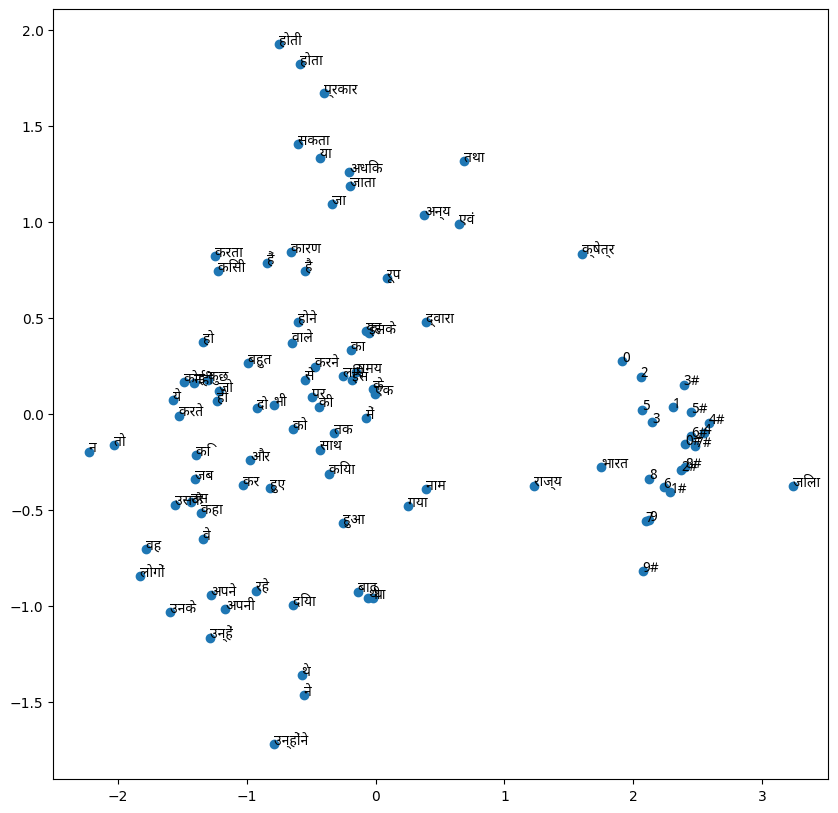

In [16]:
plt.figure(figsize=(10, 10))
plt.scatter(reduced[:, 0], reduced[:, 1])

for i, word in enumerate(word_int["Word"].iloc[:100]):
    plt.annotate(word, (reduced[i, 0], reduced[i, 1]), fontproperties=font_prop)

plt.show()

In [17]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
reduced = tsne.fit_transform(testing_points)

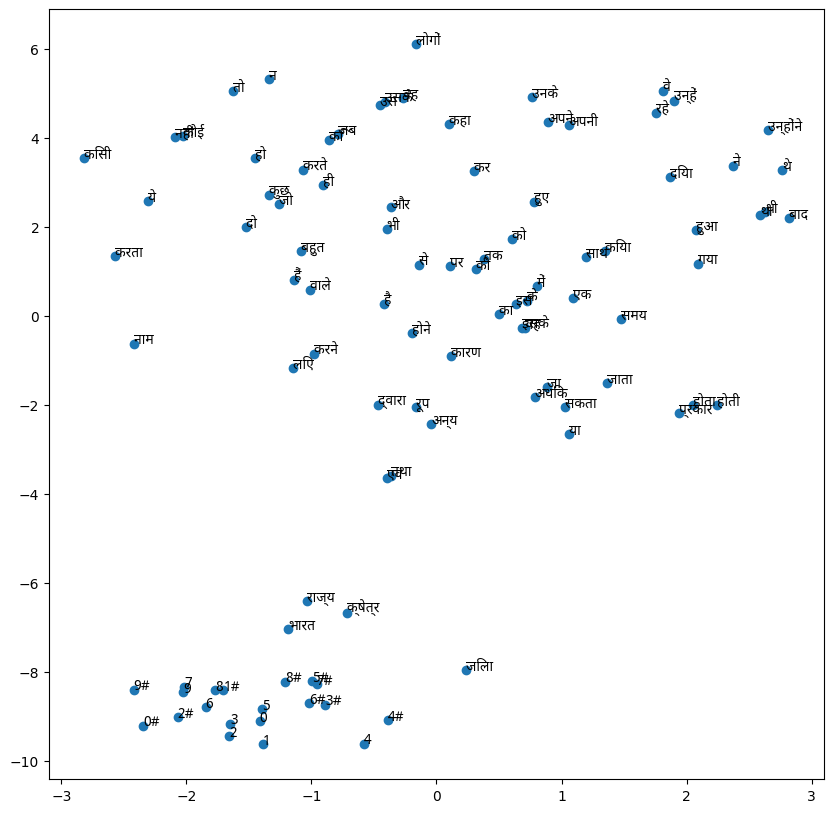

In [18]:
plt.figure(figsize=(10, 10))
plt.scatter(reduced[:, 0], reduced[:, 1])

for i, word in enumerate(word_int["Word"].iloc[:100]):
    plt.annotate(word, (reduced[i, 0], reduced[i, 1]), fontproperties=font_prop)

plt.show()

#### Embeddings = Output_layer

In [19]:
embeddings = model.state_dict()['output_embedding_layer.weight'].detach().cpu()

In [20]:
testing_points = embeddings[:100]

In [21]:
pca = PCA(n_components=2)
reduced = pca.fit_transform(testing_points)

In [22]:
word_int["Word"].iloc[:100]

,Word
0,के
1,है
2,में
3,की
4,और
...,...
95,लोगों
96,क्षेत्र
97,उन्हें
98,9


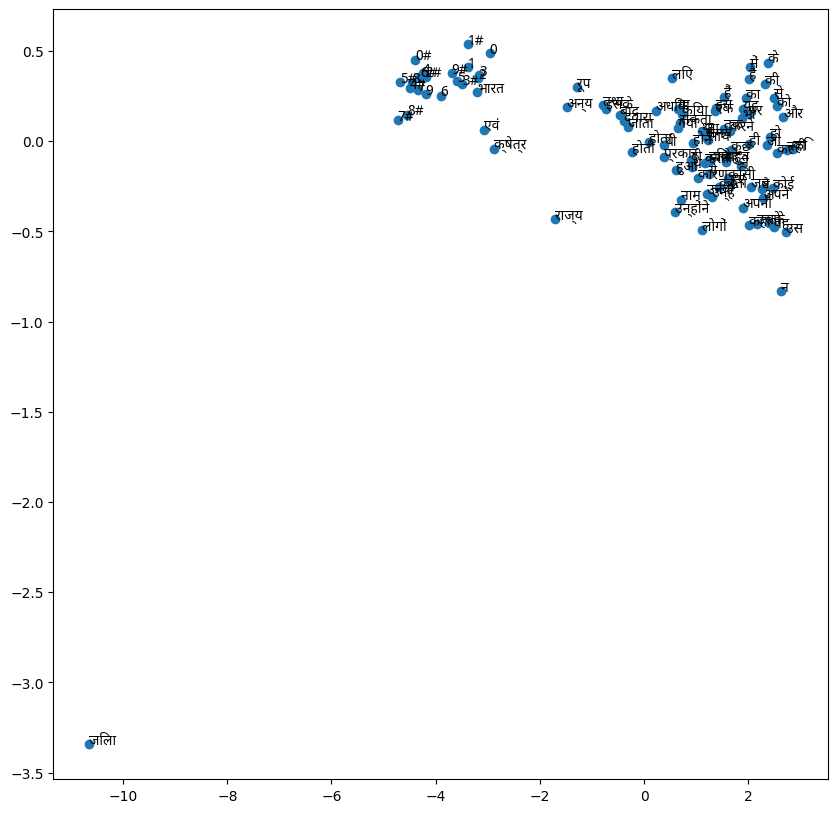

In [23]:
plt.figure(figsize=(10, 10))
plt.scatter(reduced[:, 0], reduced[:, 1])

for i, word in enumerate(word_int["Word"].iloc[:100]):
    plt.annotate(word, (reduced[i, 0], reduced[i, 1]), fontproperties=font_prop)

plt.show()

In [24]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
reduced = tsne.fit_transform(testing_points)

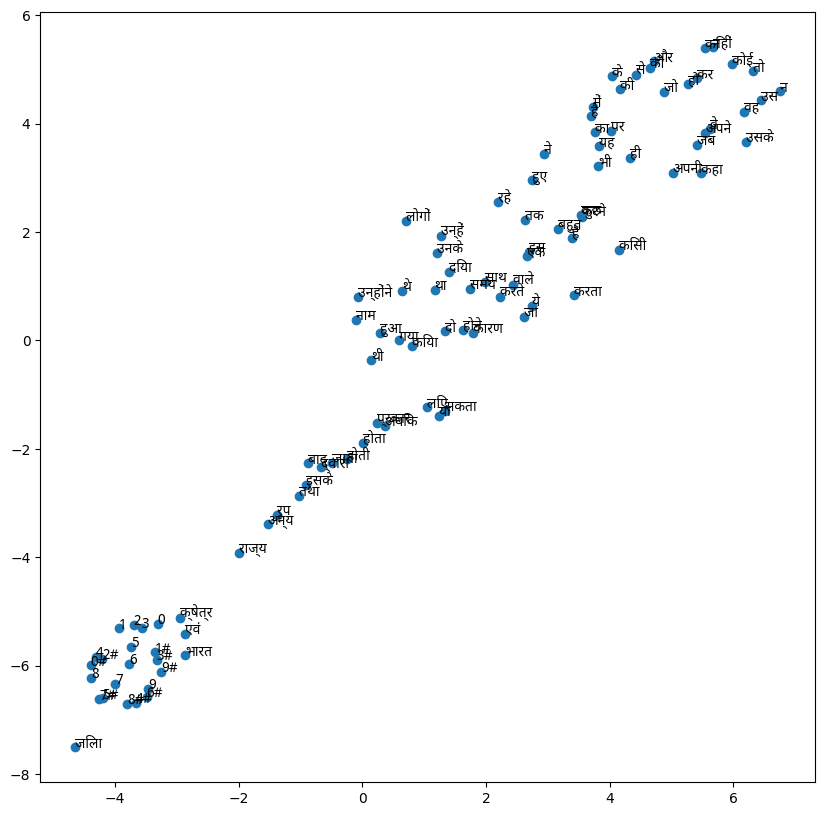

In [25]:
plt.figure(figsize=(10, 10))
plt.scatter(reduced[:, 0], reduced[:, 1])

for i, word in enumerate(word_int["Word"].iloc[:100]):
    plt.annotate(word, (reduced[i, 0], reduced[i, 1]), fontproperties=font_prop)

plt.show()

#### Embeddings = norm(input_layer+output_layer)

In [28]:
embeddings = normalize(model.state_dict()['input_embedding_layer.weight'].detach().cpu() + model.state_dict()['output_embedding_layer.weight'].detach().cpu())

In [29]:
testing_points = embeddings[:100]

In [30]:
pca = PCA(n_components=2)
reduced = pca.fit_transform(testing_points)

In [31]:
word_int["Word"].iloc[:100]

,Word
0,के
1,है
2,में
3,की
4,और
...,...
95,लोगों
96,क्षेत्र
97,उन्हें
98,9


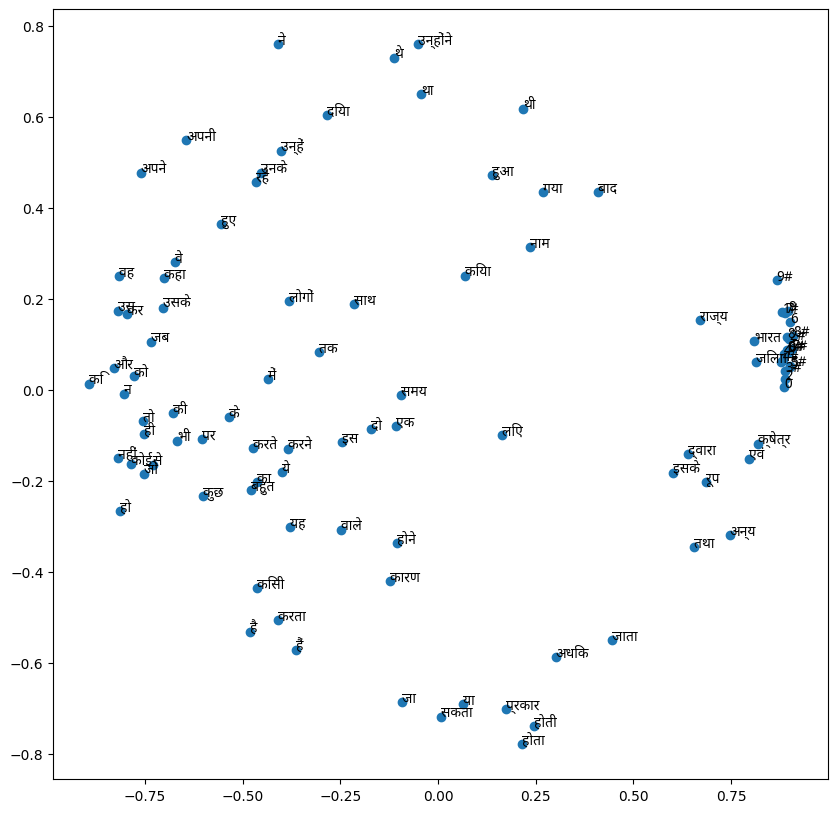

In [32]:
plt.figure(figsize=(10, 10))
plt.scatter(reduced[:, 0], reduced[:, 1])

for i, word in enumerate(word_int["Word"].iloc[:100]):
    plt.annotate(word, (reduced[i, 0], reduced[i, 1]), fontproperties=font_prop)

plt.show()

In [33]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
reduced = tsne.fit_transform(testing_points)

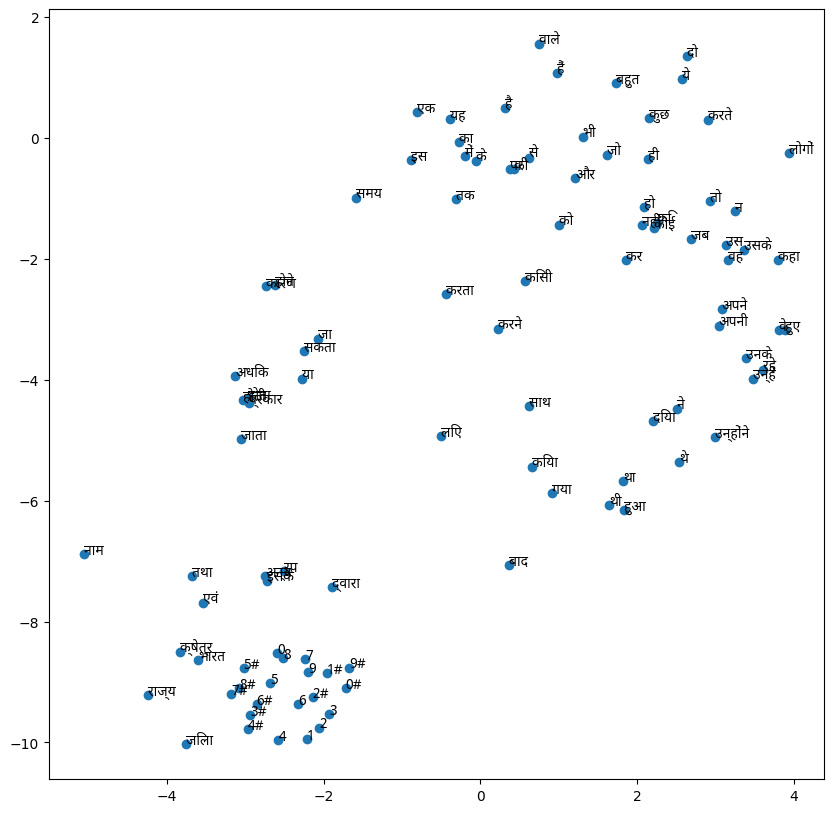

In [34]:
plt.figure(figsize=(10, 10))
plt.scatter(reduced[:, 0], reduced[:, 1])

for i, word in enumerate(word_int["Word"].iloc[:100]):
    plt.annotate(word, (reduced[i, 0], reduced[i, 1]), fontproperties=font_prop)

plt.show()